In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

print("Predictive Maintenance Case Study")
print("All libraries imported successfully!")

Predictive Maintenance Case Study
All libraries imported successfully!


In [2]:
import pandas as pd
import numpy as np

np.random.seed(42)
n = 200

df = pd.DataFrame({
    "Equipment_ID": [f"EQ{i:03d}" for i in range(1, n + 1)],
    "Equipment_Type": np.random.choice(
        ["Computer", "Printer", "Network Device"], n
    ),
    "Usage_Hours": np.random.randint(1, 17, n),
    "Temperature": np.random.randint(30, 86, n),
    "Fault_Count": np.random.randint(0, 8, n),
    "Equipment_Age": np.random.randint(1, 11, n)
})

score = (
    (df["Usage_Hours"] >= 12).astype(int)
    + (df["Temperature"] >= 65).astype(int)
    + (df["Fault_Count"] >= 4).astype(int)
    + (df["Equipment_Age"] >= 6).astype(int)
)

df["Maintenance_Risk"] = np.where(
    score >= 3, "High",
    np.where(score >= 1, "Medium", "Low")
)

df.to_csv("equipment_data.csv", index=False)

print("Dataset created successfully!")
print("Dataset shape:", df.shape)
display(df.head(10))

Dataset created successfully!
Dataset shape: (200, 7)


,Equipment_ID,Equipment_Type,Usage_Hours,Temperature,Fault_Count,Equipment_Age,Maintenance_Risk
0,EQ001,Network Device,4,78,2,10,Medium
1,EQ002,Computer,1,46,3,4,Low
2,EQ003,Network Device,14,73,7,8,High
3,EQ004,Network Device,1,57,3,9,Medium
4,EQ005,Computer,10,59,1,7,Medium
5,EQ006,Computer,4,58,2,1,Low
6,EQ007,Network Device,12,75,3,3,Medium
7,EQ008,Printer,14,82,0,9,High
8,EQ009,Network Device,7,35,0,1,Low
9,EQ010,Network Device,2,64,4,9,Medium


In [3]:
# Step 4: Data Preprocessing

# Check dataset information
print("Dataset Information:")
df.info()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate records:", df.duplicated().sum())

# Remove duplicate records if any
df = df.drop_duplicates().copy()

# Check statistical summary
print("\nStatistical Summary:")
display(df.describe())

# Check maintenance risk distribution
print("\nMaintenance Risk Distribution:")
print(df["Maintenance_Risk"].value_counts())

print("\nPreprocessing completed successfully!")

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Equipment_ID      200 non-null    object
 1   Equipment_Type    200 non-null    object
 2   Usage_Hours       200 non-null    int32 
 3   Temperature       200 non-null    int32 
 4   Fault_Count       200 non-null    int32 
 5   Equipment_Age     200 non-null    int32 
 6   Maintenance_Risk  200 non-null    object
dtypes: int32(4), object(3)
memory usage: 7.9+ KB

Missing values:
Equipment_ID        0
Equipment_Type      0
Usage_Hours         0
Temperature         0
Fault_Count         0
Equipment_Age       0
Maintenance_Risk    0
dtype: int64

Duplicate records: 0

Statistical Summary:


,Usage_Hours,Temperature,Fault_Count,Equipment_Age
count,200.000000,200.000000,200.000000,200.000000
mean,7.850000,59.300000,3.170000,5.300000
std,5.002261,16.041717,2.185172,2.970542
min,1.000000,30.000000,0.000000,1.000000
25%,3.000000,46.750000,1.000000,3.000000
50%,7.000000,59.500000,3.000000,5.000000
75%,12.000000,74.000000,5.000000,8.000000
max,16.000000,85.000000,7.000000,10.000000



Maintenance Risk Distribution:
Maintenance_Risk
Medium    132
High       37
Low        31
Name: count, dtype: int64

Preprocessing completed successfully!


K-Means clustering completed!

Equipment count in each cluster:
Cluster
0    62
1    72
2    66
Name: count, dtype: int64

Sample cluster assignments:


C:\Users\tanvi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,Equipment_ID,Usage_Hours,Temperature,Fault_Count,Equipment_Age,Cluster
0,EQ001,4,78,2,10,0
1,EQ002,1,46,3,4,1
2,EQ003,14,73,7,8,0
3,EQ004,1,57,3,9,0
4,EQ005,10,59,1,7,2
5,EQ006,4,58,2,1,1
6,EQ007,12,75,3,3,2
7,EQ008,14,82,0,9,2
8,EQ009,7,35,0,1,1
9,EQ010,2,64,4,9,0


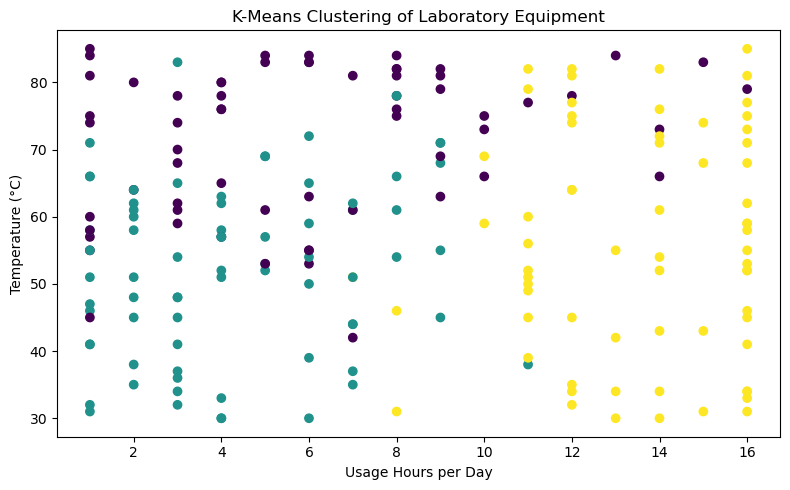

In [4]:
# Step 5: K-Means Clustering

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Select numerical features
features = [
    "Usage_Hours",
    "Temperature",
    "Fault_Count",
    "Equipment_Age"
]

X = df[features]

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply K-Means clustering
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

# Display cluster results
print("K-Means clustering completed!")
print("\nEquipment count in each cluster:")
print(df["Cluster"].value_counts().sort_index())

print("\nSample cluster assignments:")
display(df[[
    "Equipment_ID",
    "Usage_Hours",
    "Temperature",
    "Fault_Count",
    "Equipment_Age",
    "Cluster"
]].head(10))

# Visualize clusters
plt.figure(figsize=(8, 5))
plt.scatter(
    df["Usage_Hours"],
    df["Temperature"],
    c=df["Cluster"]
)
plt.xlabel("Usage Hours per Day")
plt.ylabel("Temperature (°C)")
plt.title("K-Means Clustering of Laboratory Equipment")
plt.tight_layout()
plt.show()

Decision Tree Classification Completed!
Accuracy: 97.5 %

Classification Report:
              precision    recall  f1-score   support

        High       1.00      0.88      0.93         8
         Low       1.00      1.00      1.00         6
      Medium       0.96      1.00      0.98        26

    accuracy                           0.97        40
   macro avg       0.99      0.96      0.97        40
weighted avg       0.98      0.97      0.97        40



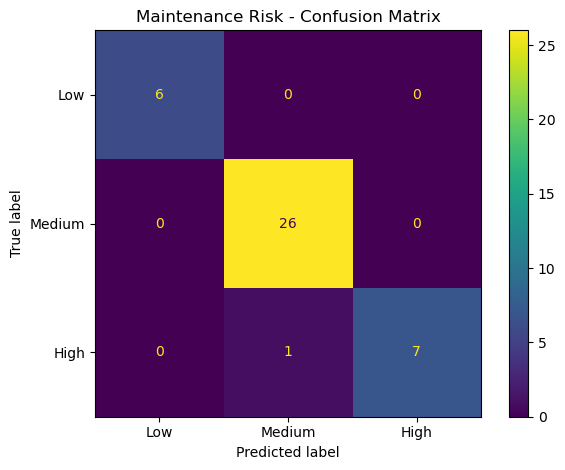

In [5]:
# Step 6: Decision Tree Classification

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Select input features and target
X = df[[
    "Usage_Hours",
    "Temperature",
    "Fault_Count",
    "Equipment_Age"
]]
y = df["Maintenance_Risk"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Train the model
model = DecisionTreeClassifier(
    max_depth=5, random_state=42
)
model.fit(X_train, y_train)

# Predict maintenance risk
y_pred = model.predict(X_test)

# Evaluate the model
print("Decision Tree Classification Completed!")
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Display confusion matrix
cm = confusion_matrix(
    y_test, y_pred, labels=["Low", "Medium", "High"]
)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low", "Medium", "High"]
)
disp.plot()
plt.title("Maintenance Risk - Confusion Matrix")
plt.tight_layout()
plt.show()

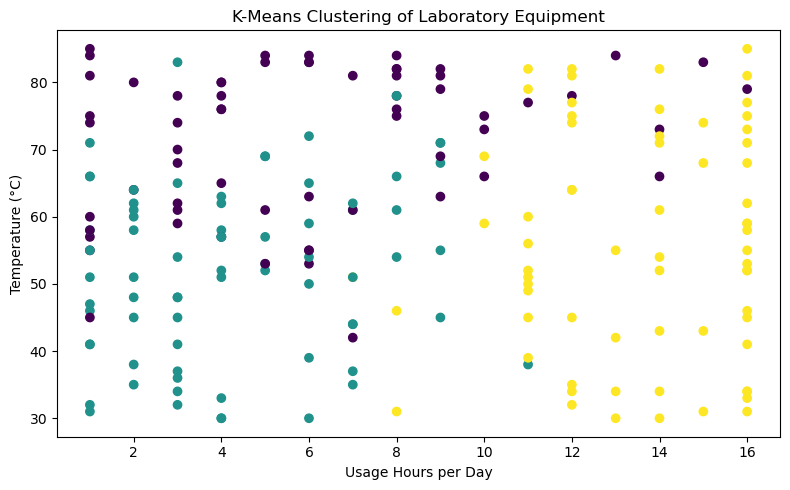

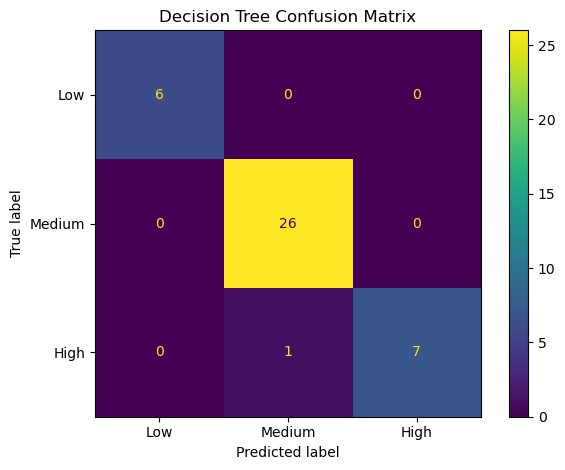

Results, graphs and models saved successfully!


In [6]:
import os
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Create project output folder
os.makedirs("results", exist_ok=True)

# Save dataset with cluster labels
df.to_csv("results/equipment_results.csv", index=False)

# Save clustering graph
plt.figure(figsize=(8, 5))
plt.scatter(
    df["Usage_Hours"],
    df["Temperature"],
    c=df["Cluster"]
)
plt.xlabel("Usage Hours per Day")
plt.ylabel("Temperature (°C)")
plt.title("K-Means Clustering of Laboratory Equipment")
plt.tight_layout()
plt.savefig("results/kmeans_clusters.png", dpi=150)
plt.show()

# Save confusion matrix graph
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    labels=["Low", "Medium", "High"],
    display_labels=["Low", "Medium", "High"]
)
plt.title("Decision Tree Confusion Matrix")
plt.tight_layout()
plt.savefig("results/confusion_matrix.png", dpi=150)
plt.show()

# Save trained model and scaler
joblib.dump(model, "results/decision_tree_model.pkl")
joblib.dump(kmeans, "results/kmeans_model.pkl")
joblib.dump(scaler, "results/scaler.pkl")

print("Results, graphs and models saved successfully!")

In [7]:
import os
print("Current folder:", os.getcwd())
print("\nFiles available:")
print(os.listdir())

Current folder: C:\Users\tanvi\Predictive_Maintenance

Files available:
['.ipynb_checkpoints', 'equipment_data.csv', 'Predictive_Maintenance_CCE2.ipynb', 'results']
